# LC4 の頭打ちをシグモイドにする

`loom_type_split.ipynb` では、LC4 の発火率を拡大速度の直線で上げ、50 rad/s で 80 Hz に切り落としていた。LPLC2 は視角 40° を山にするガウス関数のままにする。50 Hz と 80 Hz も変えない。

切り落としの角は 50 rad/s にある。片眼の looming が届かなかったのは、拡大速度が 12 rad/s ほどの直線部分である。角を丸めるだけでは、その速度の値は上がらない。立ち上がりの中心を遅いほうへ移すと、そこが上がる。両方を同じ幾何で比べる。

どちらのシグモイドも、拡大速度 0 で 0、速い極限で 1 になるように端を合わせる。

$$
\sigma(\dot\theta) = \frac{1}{1 + \exp(-(\dot\theta - m)/w)}, \qquad
s(\dot\theta) = \frac{\sigma(\dot\theta) - \sigma(0)}{1 - \sigma(0)}
$$

滑らかは、直線の途中に合わせたもので、中心 \(m = 25\) rad/s、幅 \(w = 8\) rad/s である。早めたは、片眼が埋まる 12 rad/s 付近を持ち上げるもので、中心 \(m = 8\) rad/s、幅 \(w = 5\) rad/s である。どちらも計測のフィットではない。

$$
r^{\mathrm{LC4}}_i = 80\,\mathrm{Hz}\, s(\dot\theta)\, f_i
$$

LPLC2 と \(W_{\mathrm{side}}\) で割る電流は、分けた式のままである。


In [1]:
from pathlib import Path
import sys

import japanize_matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.feather as feather

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "data" / "malecns" / "gf-loom" / "neurons.feather").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from flycar.fov import Scene

DATA = ROOT / "data" / "malecns" / "gf-loom"
LC4_CACHE = ROOT / "data" / "malecns" / "lc4-camera" / "lc4_lobula_posts.npz"
LPLC2_CACHE = ROOT / "data" / "malecns" / "lplc2-camera" / "lplc2_lobula_posts.npz"
R_MAX, R_REF, THETA_DOT_SAT = 80.0, 50.0, 50.0
SCALE = R_MAX / R_REF
SIZE_PEAK_DEG, SIZE_SIGMA_DEG = 40.0, 20.0
SMOOTH_MID, SMOOTH_WIDTH = 25.0, 8.0
EARLY_MID, EARLY_WIDTH = 8.0, 5.0
TAU_MS, V_THRESHOLD, REFRAC_MS = 5.0, 1.0, 5.0
DT, GEOM_DT = 0.001, 0.005
if abs(GEOM_DT / DT - round(GEOM_DT / DT)) > 1e-9:
    raise RuntimeError("幾何の刻みが膜の刻みの整数倍でない。")
REPEATS = int(round(GEOM_DT / DT))
CHUNK = 8


## 細胞とカメラ

位置とシナプス数は `loom_threshold.ipynb` と同じである。


In [3]:
def image_uv(ab, side, left_ab, right_ab):
    # u is 0 at the left edge and 1 at the right edge. v is 0 at the top.
    u = np.empty(len(ab), dtype=np.float64)
    v = np.empty(len(ab), dtype=np.float64)
    for code_side, grid in ((0, left_ab), (1, right_ab)):
        valid = grid[:, 0] >= 0
        a0, a1 = grid[valid, 0].min(), grid[valid, 0].max()
        b0, b1 = grid[valid, 1].min(), grid[valid, 1].max()
        mask = side == code_side
        lateral = (ab[mask, 0] - a0) / (a1 - a0)
        if code_side == 0:
            u[mask] = 0.5 * (1.0 - lateral)
        else:
            u[mask] = 0.5 + 0.5 * lateral
        v[mask] = (ab[mask, 1] - b0) / (b1 - b0)
    return u, v


def load_population(pack, keys, weight_of, side_of):
    body = pack[keys[0]]
    ab = pack[keys[1]]
    side = pack[keys[2]]
    u, v = image_uv(ab, side, pack[keys[3]], pack[keys[4]])
    order = np.argsort(body, kind="mergesort")
    body, u, v, side = body[order], u[order], v[order], side[order]
    if np.any((u < -1e-9) | (u > 1 + 1e-9) | (v < -1e-9) | (v > 1 + 1e-9)):
        raise RuntimeError("画面の外に出る後シナプスがある。")
    cuts = np.flatnonzero(np.diff(body)) + 1
    starts = np.r_[0, cuts]
    cell_n = np.diff(np.r_[starts, len(body)]).astype(np.float64)
    cell_id = body[starts]
    cell_side = side[starts]
    if np.any(np.maximum.reduceat(side, starts) != np.minimum.reduceat(side, starts)):
        raise RuntimeError("片眼に収まらない細胞がある。")
    names = side_of.loc[cell_id].to_numpy()
    expect = np.where(names == "L", np.int8(0), np.int8(1))
    if not np.array_equal(expect, cell_side):
        raise RuntimeError("画面の左右と注釈の左右が違う。")
    missing = [int(i) for i in cell_id if int(i) not in weight_of]
    if missing:
        raise RuntimeError(f"DNp01 への辺が無い細胞がある。先頭 {missing[:5]}")
    cell_w = np.array([weight_of[int(i)] for i in cell_id], dtype=np.float64)
    return {
        "u": np.ascontiguousarray(u),
        "v": np.ascontiguousarray(v),
        "starts": starts,
        "n": cell_n,
        "id": cell_id,
        "side": cell_side,
        "w": cell_w,
        "sum": np.array([cell_w[cell_side == code].sum() for code in (0, 1)]),
    }


neurons = feather.read_table(DATA / "neurons.feather").to_pandas()
edges = feather.read_table(DATA / "edges.feather").to_pandas()
gf = neurons.loc[neurons.type == "DNp01", ["bodyId", "side"]].rename(
    columns={"bodyId": "body_post", "side": "side_post"}
)
side_of = neurons.set_index("bodyId")["side"]


def weight_onto(type_name):
    pre = neurons.loc[neurons.type == type_name, ["bodyId", "side"]].rename(
        columns={"bodyId": "body_pre", "side": "side_pre"}
    )
    part = edges.merge(pre, on="body_pre").merge(gf, on="body_post")
    if not (part.side_pre == part.side_post).all():
        raise RuntimeError(f"対側への {type_name} → DNp01 がある。")
    if not part.nt_sign.eq(1).all():
        raise RuntimeError(f"{type_name} → DNp01 にアセチルコリン以外がある。")
    return dict(zip(part.body_pre.astype(np.int64), part.weight.astype(np.float64)))


lc4 = load_population(
    np.load(LC4_CACHE),
    ("body", "ab", "side", "left_ab", "right_ab"),
    weight_onto("LC4"),
    side_of,
)
lplc = load_population(
    np.load(LPLC2_CACHE),
    ("lop_body", "lop_ab", "lop_side", "lop_left_ab", "lop_right_ab"),
    weight_onto("LPLC2"),
    side_of,
)
side_ref = lc4["sum"] + lplc["sum"]
for index, name in ((0, "左"), (1, "右")):
    print(
        f"{name}  基準 {side_ref[index]:.0f}"
        f"  LC4 上限 {lc4['sum'][index] / side_ref[index] * SCALE:.3f}"
        f"  LPLC2 上限 {lplc['sum'][index] / side_ref[index] * SCALE:.3f}"
    )

scene = Scene()
hfov, vfov = scene.fovs()
pitch = float(np.deg2rad(scene.pitch_deg))
cam = np.array([0.0, 0.0, scene.cam_h])
forward = np.array([1.0, 0.0, 0.0])
left = np.array([0.0, 1.0, 0.0])
up = np.array([0.0, 0.0, 1.0])
optical = forward * np.cos(pitch) - up * np.sin(pitch)
cam_up = forward * np.sin(pitch) + up * np.cos(pitch)
cam_right = -left
tan_h = float(np.tan(hfov / 2.0))
tan_v = float(np.tan(vfov / 2.0))
print(f"水平 {np.rad2deg(hfov):.1f}°  垂直 {np.rad2deg(vfov):.1f}°")


左  基準 6424  LC4 上限 0.942  LPLC2 上限 0.658
右  基準 4800  LC4 上限 0.860  LPLC2 上限 0.740
水平 51.6°  垂直 30.4°


## 電流

幾何は 5 ms、膜は 1 ms、時定数 5 ms、閾値 1、不応期 5 ms である。


In [5]:
def covered_weight(pop, cu, cv, ru, rv, active):
    out = np.zeros((len(cu), 2), dtype=np.float64)
    idx = np.flatnonzero(active)
    syn_u, syn_v = pop["u"], pop["v"]
    starts, cell_n = pop["starts"], pop["n"]
    masks = [pop["side"] == 0, pop["side"] == 1]
    weights = [pop["w"][mask] for mask in masks]
    for start in range(0, len(idx), CHUNK):
        sel = idx[start:start + CHUNK]
        du = (syn_u[None, :] - cu[sel, None]) / ru[sel, None]
        dv = (syn_v[None, :] - cv[sel, None]) / rv[sel, None]
        inside = ((du * du + dv * dv) <= 1.0).astype(np.float64)
        frac = np.add.reduceat(inside, starts, axis=1) / cell_n
        for code_side in (0, 1):
            out[sel, code_side] = frac[:, masks[code_side]] @ weights[code_side]
    return out


def project_many(positions, radius):
    rel = positions - cam
    depth = rel @ optical
    valid = depth > 1e-4
    depth_safe = np.where(valid, depth, np.inf)
    nx = (rel @ cam_right) / depth_safe / tan_h
    ny = (rel @ cam_up) / depth_safe / tan_v
    cu = (nx + 1.0) / 2.0
    cv = (1.0 - ny) / 2.0
    ru = (radius / depth_safe) / tan_h / 2.0
    rv = (radius / depth_safe) / tan_v / 2.0
    active = (
        valid
        & (ru > 1e-8)
        & (rv > 1e-8)
        & (cu + ru >= 0.0)
        & (cu - ru <= 1.0)
        & (cv + rv >= 0.0)
        & (cv - rv <= 1.0)
    )
    return cu, cv, ru, rv, active


def expansion_many(positions, velocity, radius):
    rel = positions - cam
    dist = np.linalg.norm(rel, axis=1)
    theta = 2.0 * np.arctan(radius / dist)
    closing = -(rel @ velocity) / dist
    theta_dot = np.maximum(2.0 * radius * closing / (dist * dist + radius * radius), 0.0)
    return theta, theta_dot


def size_gain(theta):
    deg = np.rad2deg(theta)
    return np.exp(-0.5 * ((deg - SIZE_PEAK_DEG) / SIZE_SIGMA_DEG) ** 2)


def anchored_sigmoid(theta_dot, mid, width):
    raw = 1.0 / (1.0 + np.exp(-(theta_dot - mid) / width))
    raw0 = 1.0 / (1.0 + np.exp(mid / width))
    return (raw - raw0) / (1.0 - raw0)


def lif_count(drive):
    v = 0.0
    silent_until = 0
    refrac_steps = int(round(REFRAC_MS / (DT * 1000)))
    step = (DT * 1000) / TAU_MS
    count = 0
    voltage = np.empty(len(drive))
    for i, value in enumerate(drive):
        if i < silent_until:
            v = 0.0
            voltage[i] = 0.0
            continue
        v += step * (-v + float(value))
        if v >= V_THRESHOLD:
            voltage[i] = V_THRESHOLD
            count += 1
            v = 0.0
            silent_until = i + refrac_steps
        else:
            voltage[i] = v
    return count, voltage


def approach_path(radius, speed, offset, window=0.40):
    samples = int(round(window / GEOM_DT)) + 1
    distance = np.linspace(radius + speed * window, radius, samples)
    positions = cam + optical * distance[:, None] + left * offset
    return positions, -optical * speed


def passage_path(radius, speed, distance):
    half = distance * tan_h + radius + 0.05
    samples = int(round(2.0 * half / speed / GEOM_DT)) + 1
    lateral = np.linspace(half, -half, samples)
    positions = cam + optical * distance + left * lateral[:, None]
    return positions, -left * speed


def simulate(positions, velocity, radius, keep=False):
    theta, theta_dot = expansion_many(positions, velocity, radius)
    cu, cv, ru, rv, active = project_many(positions, radius)
    w_lc4 = covered_weight(lc4, cu, cv, ru, rv, active)
    w_lplc = covered_weight(lplc, cu, cv, ru, rv, active)
    clip = np.clip(theta_dot / THETA_DOT_SAT, 0.0, 1.0)
    smooth = anchored_sigmoid(theta_dot, SMOOTH_MID, SMOOTH_WIDTH)
    early = anchored_sigmoid(theta_dot, EARLY_MID, EARLY_WIDTH)
    gain = size_gain(theta)
    size_drive = gain[:, None] * SCALE * w_lplc / side_ref
    lc4_base = SCALE * w_lc4 / side_ref
    currents = {
        "クリップ": clip[:, None] * lc4_base + size_drive,
        "滑らか": smooth[:, None] * lc4_base + size_drive,
        "早めた": early[:, None] * lc4_base + size_drive,
    }
    peak = int(np.argmax(currents["早めた"][:, 0]))
    summary = {
        "視角": float(np.rad2deg(theta.max())),
        "拡大速度": float(theta_dot.max()),
        "早めた時の視角左": float(np.rad2deg(theta[peak])),
        "早めた時の拡大左": float(theta_dot[peak]),
    }
    detail = None
    if keep:
        detail = {
            "geom_time": np.arange(len(theta)) * GEOM_DT,
            "time": np.arange(len(theta) * REPEATS) * DT,
            "current": currents,
            "voltage": {},
            "clip": clip,
            "smooth": smooth,
            "early": early,
        }
    for name, current in currents.items():
        expanded = np.repeat(current, REPEATS, axis=0)
        left_n, left_v = lif_count(expanded[:, 0])
        right_n, right_v = lif_count(expanded[:, 1])
        summary[f"{name}電流左"] = float(current[:, 0].max())
        summary[f"{name}電流右"] = float(current[:, 1].max())
        summary[f"{name}スパイク左"] = left_n
        summary[f"{name}スパイク右"] = right_n
        if keep:
            detail["voltage"][name] = np.column_stack([left_v, right_v])
    return summary, detail


speeds = np.array([0, 5, 12, 16, 25, 40, 50, 80], dtype=float)
print("拡大速度   クリップ  滑らか  早めた")
for speed in speeds:
    print(
        f"{speed:6.0f}   "
        f"{min(speed / THETA_DOT_SAT, 1):7.3f}  "
        f"{float(anchored_sigmoid(np.array([speed]), SMOOTH_MID, SMOOTH_WIDTH)[0]):7.3f}  "
        f"{float(anchored_sigmoid(np.array([speed]), EARLY_MID, EARLY_WIDTH)[0]):7.3f}"
    )


拡大速度   クリップ  滑らか  早めた
     0     0.000    0.000    0.000
     5     0.100    0.035    0.224
    12     0.240    0.128    0.627
    16     0.320    0.212    0.798
    25     0.500    0.478    0.961
    40     0.800    0.861    0.998
    50     1.000    0.956    1.000
    80     1.000    0.999    1.000


## 接近

前回と同じ格子である。正面と、左右へ 0.15 m ずらした接近。半径は 3、5、8、12、20、40 cm。速度は 0.5、1、2、4、8 m/s。


In [7]:
RADII = [0.03, 0.05, 0.08, 0.12, 0.20, 0.40]
SPEEDS = [0.5, 1.0, 2.0, 4.0, 8.0]
approach_rows = []
for offset, where in ((0.0, "正面"), (0.15, "左"), (-0.15, "右")):
    for radius in RADII:
        for speed in SPEEDS:
            positions, velocity = approach_path(radius, speed, offset)
            summary, _ = simulate(positions, velocity, radius)
            summary.update({"経路": where, "半径": radius, "速度": speed})
            approach_rows.append(summary)

approach = pd.DataFrame(approach_rows)
front_cols = [
    "半径", "速度", "視角", "拡大速度",
    "クリップ電流左", "滑らか電流左", "早めた電流左",
    "クリップスパイク左", "滑らかスパイク左", "早めたスパイク左", "早めたスパイク右",
]
print("正面")
print(approach.loc[approach["経路"].eq("正面"), front_cols].to_string(
    index=False, float_format=lambda value: f"{value:.3f}"
))
print()
offset_view = (
    approach.loc[approach["経路"].ne("正面")]
    .groupby(["経路", "半径"], as_index=False)
    .agg(
        拡大速度=("拡大速度", "max"),
        クリップ電流左=("クリップ電流左", "max"),
        滑らか電流左=("滑らか電流左", "max"),
        早めた電流左=("早めた電流左", "max"),
        早めた電流右=("早めた電流右", "max"),
        クリップスパイク左=("クリップスパイク左", "sum"),
        滑らかスパイク左=("滑らかスパイク左", "sum"),
        早めたスパイク左=("早めたスパイク左", "sum"),
        早めたスパイク右=("早めたスパイク右", "sum"),
    )
)
print("左右に 0.15 m ずらした接近。スパイクは速度 5 通りの合計")
print(offset_view.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print()
print("ずらした接近で、早めたが発火した速度")
hit = approach.loc[
    approach["経路"].ne("正面")
    & (approach["早めたスパイク左"].gt(0) | approach["早めたスパイク右"].gt(0)),
    [
        "経路", "半径", "速度", "拡大速度",
        "早めた電流左", "早めた電流右",
        "早めたスパイク左", "早めたスパイク右",
    ],
]
print(hit.to_string(index=False, float_format=lambda value: f"{value:.3f}"))


正面
   半径    速度     視角    拡大速度  クリップ電流左  滑らか電流左  早めた電流左  クリップスパイク左  滑らかスパイク左  早めたスパイク左  早めたスパイク右
0.030 0.500 90.000  16.667    0.665   0.598   0.825          0         0         0         0
0.030 1.000 90.000  33.333    0.775   0.714   1.182          0         0         2         2
0.030 2.000 90.000  66.667    1.063   1.090   1.437          1         1         2         2
0.030 4.000 90.000 133.333    1.303   1.316   1.418          1         1         1         1
0.030 8.000 90.000 266.667    1.420   1.419   1.420          1         1         1         1
0.050 0.500 90.000  10.000    0.620   0.577   0.692          0         0         0         0
0.050 1.000 90.000  20.000    0.685   0.605   0.901          0         0         0         0
0.050 2.000 90.000  40.000    0.826   0.840   1.274          0         0         3         2
0.050 4.000 90.000  80.000    1.148   1.212   1.435          1         1         2         2
0.050 8.000 90.000 160.000    1.379   1.377   1.379          1     

## 通過

距離 0.30 m、0.50 m、1.0 m。速度 0.5、2、8 m/s。早めたシグモイドは遅い拡大でも LC4 を上げるので、通過で新たに発火するかを見る。


In [9]:
DISTANCES = [0.30, 0.50, 1.00]
PASS_SPEEDS = [0.5, 2.0, 8.0]
passage_rows = []
for distance in DISTANCES:
    for radius in RADII:
        for speed in PASS_SPEEDS:
            positions, velocity = passage_path(radius, speed, distance)
            summary, _ = simulate(positions, velocity, radius)
            summary.update({"距離": distance, "半径": radius, "速度": speed})
            passage_rows.append(summary)

passage = pd.DataFrame(passage_rows)
peak = (
    passage.groupby(["距離", "半径"], as_index=False)
    .agg(
        視角=("視角", "max"),
        拡大速度=("拡大速度", "max"),
        クリップ電流=("クリップ電流左", "max"),
        滑らか電流=("滑らか電流左", "max"),
        早めた電流=("早めた電流左", "max"),
        クリップスパイク=("クリップスパイク左", "sum"),
        滑らかスパイク=("滑らかスパイク左", "sum"),
        早めたスパイク=("早めたスパイク左", "sum"),
        右の早めたスパイク=("早めたスパイク右", "sum"),
    )
)
print(peak.to_string(index=False, float_format=lambda value: f"{value:.3f}"))


   距離    半径      視角   拡大速度  クリップ電流  滑らか電流  早めた電流  クリップスパイク  滑らかスパイク  早めたスパイク  右の早めたスパイク
0.300 0.030  11.421  2.035   0.071  0.070  0.072         0        0        0          0
0.300 0.050  18.925  3.354   0.276  0.260  0.298         0        0        0          0
0.300 0.080  29.863  5.204   0.597  0.559  0.655         0        0        0          0
0.300 0.120  43.603  7.414   0.766  0.697  0.913         0        0        0          0
0.300 0.200  67.380 10.655   0.630  0.543  0.943         0        0        0          0
0.300 0.400 106.260 13.290   0.348  0.248  0.728         0        0        0          0
0.500 0.030   6.867  0.733   0.020  0.020  0.020         0        0        0          0
0.500 0.050  11.421  1.222   0.072  0.070  0.075         0        0        0          0
0.500 0.080  18.181  1.935   0.245  0.235  0.255         0        0        0          0
0.500 0.120  26.991  2.845   0.510  0.489  0.536         0        0        0          0
0.500 0.200  43.603  4.459   0.7

## 波形

左は正面の 5 cm、2 m/s。右は左へ 0.15 m ずらした 20 cm、8 m/s である。破線がクリップ、細線が角を丸めたシグモイド、太線が立ち上がりを早めたシグモイドである。


正面 5 cm、2 m/s  視角 90°  拡大 40.0  クリップ 0.83 スパイク 0/0  滑らか 0.84 スパイク 0/0  早めた 1.27 スパイク 3/2  早めたの山は視角 53° 拡大 16.0
左 20 cm、8 m/s  視角 77°  拡大 25.0  クリップ 0.85 スパイク 0/0  滑らか 0.74 スパイク 0/0  早めた 1.24 スパイク 4/0  早めたの山は視角 54° 拡大 15.4


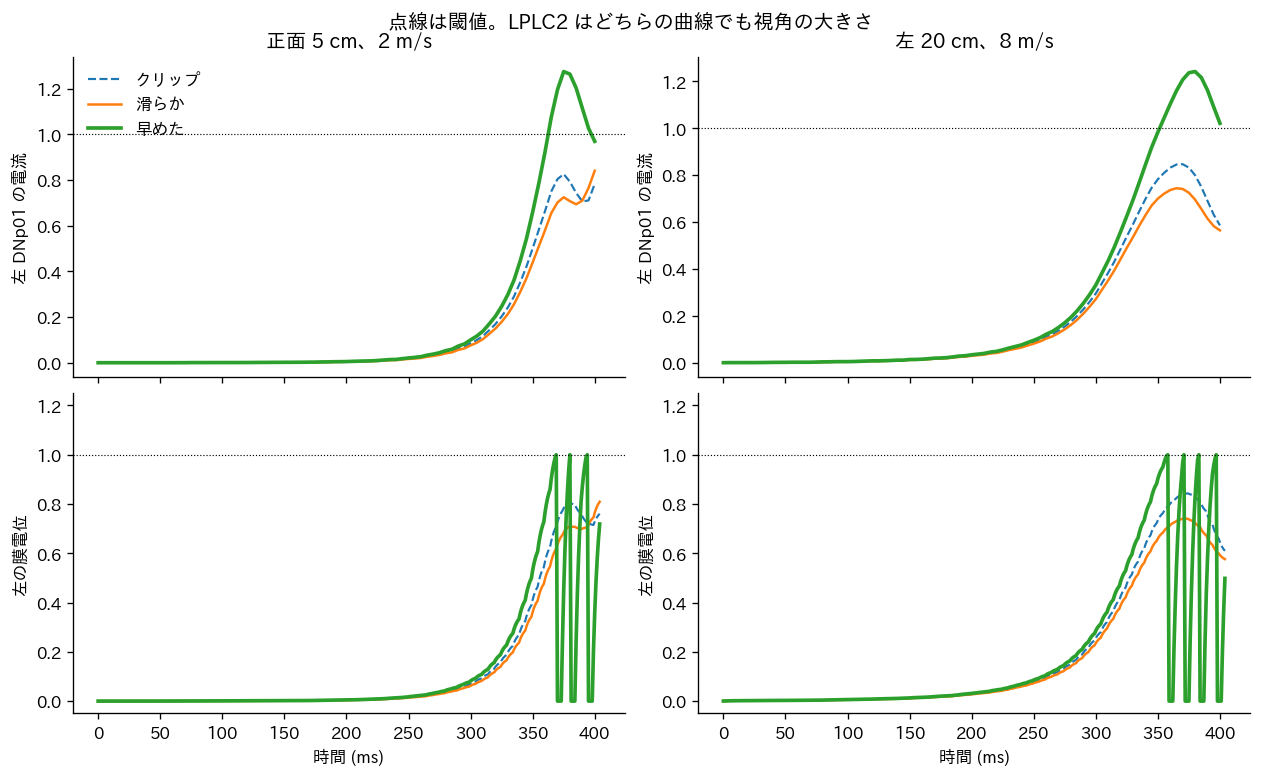

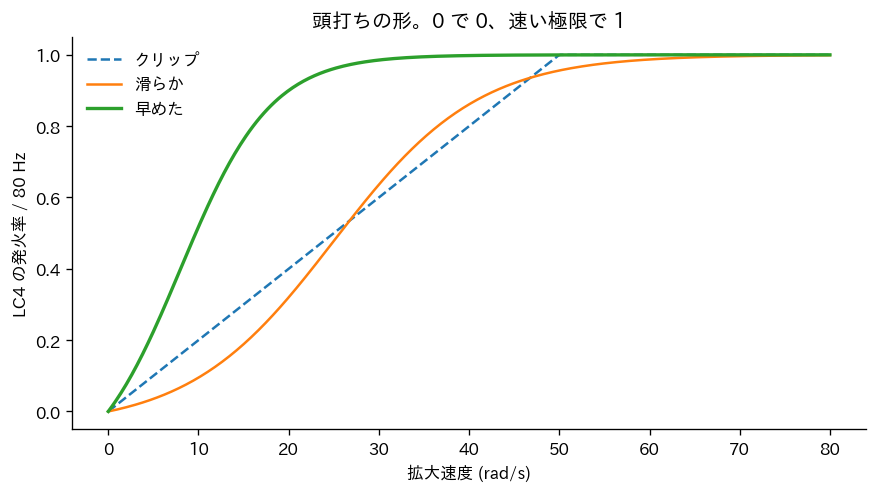

In [11]:
examples = []
for label, positions, velocity, radius in (
    ("正面 5 cm、2 m/s", *approach_path(0.05, 2.0, 0.0), 0.05),
    ("左 20 cm、8 m/s", *approach_path(0.20, 8.0, 0.15), 0.20),
):
    summary, detail = simulate(positions, velocity, radius, keep=True)
    examples.append((label, summary, detail))
    print(
        f"{label}  視角 {summary['視角']:.0f}°  拡大 {summary['拡大速度']:.1f}  "
        f"クリップ {summary['クリップ電流左']:.2f} スパイク {summary['クリップスパイク左']}/{summary['クリップスパイク右']}  "
        f"滑らか {summary['滑らか電流左']:.2f} スパイク {summary['滑らかスパイク左']}/{summary['滑らかスパイク右']}  "
        f"早めた {summary['早めた電流左']:.2f} スパイク {summary['早めたスパイク左']}/{summary['早めたスパイク右']}  "
        f"早めたの山は視角 {summary['早めた時の視角左']:.0f}° 拡大 {summary['早めた時の拡大左']:.1f}"
    )

fig, axes = plt.subplots(2, 2, figsize=(10.4, 6.2), sharex="col", constrained_layout=True)
styles = (("クリップ", 1.3, "--"), ("滑らか", 1.5, "-"), ("早めた", 2.2, "-"))
for column, (label, summary, detail) in enumerate(examples):
    time_ms = detail["geom_time"] * 1000
    membrane_ms = detail["time"] * 1000
    for name, width, linestyle in styles:
        axes[0, column].plot(time_ms, detail["current"][name][:, 0], lw=width, ls=linestyle, label=name)
        axes[1, column].plot(membrane_ms, detail["voltage"][name][:, 0], lw=width, ls=linestyle)
    for row in range(2):
        axes[row, column].axhline(1.0, color="k", lw=0.7, ls=":")
        axes[row, column].spines["top"].set_visible(False)
        axes[row, column].spines["right"].set_visible(False)
    axes[0, column].set_title(label)
    axes[0, column].set_ylabel("左 DNp01 の電流")
    axes[1, column].set_ylabel("左の膜電位")
    axes[1, column].set_ylim(-0.05, 1.25)
    axes[1, column].set_xlabel("時間 (ms)")
axes[0, 0].legend(frameon=False, loc="upper left")
fig.suptitle("点線は閾値。LPLC2 はどちらの曲線でも視角の大きさ", y=1.02)
plt.show()

curve_speed = np.linspace(0, 80, 400)
fig, ax = plt.subplots(figsize=(7.2, 4.0), constrained_layout=True)
ax.plot(curve_speed, np.clip(curve_speed / THETA_DOT_SAT, 0, 1), ls="--", label="クリップ")
ax.plot(curve_speed, anchored_sigmoid(curve_speed, SMOOTH_MID, SMOOTH_WIDTH), label="滑らか")
ax.plot(curve_speed, anchored_sigmoid(curve_speed, EARLY_MID, EARLY_WIDTH), lw=2, label="早めた")
ax.set_xlabel("拡大速度 (rad/s)")
ax.set_ylabel("LC4 の発火率 / 80 Hz")
ax.set_title("頭打ちの形。0 で 0、速い極限で 1")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()


## 読み方

50 Hz、80 Hz、LPLC2 のガウス関数は動かしていない。変えたのは LC4 の頭打ちだけである。シグモイドは拡大速度 0 で 0、速い極限で 1 になるよう端を合わせた。中心と幅は計測のフィットではない。

角を丸めただけ（中心 25 rad/s、幅 8 rad/s）では、12 rad/s の係数がクリップの 0.24 から 0.13 に下がる。正面で発火する行はクリップと同じで、左右に 0.15 m ずらした接近も通過も 0 回のままである。片眼の 20 cm、8 m/s では電流が 0.85 から 0.74 に下がる。

立ち上がりを早めたほう（中心 8 rad/s、幅 5 rad/s）は、12 rad/s の係数が 0.63 になる。この中心と幅は、片眼が埋まる 12 rad/s 付近を閾値の上へ運ぶように置いた値である。正面の 5 cm、2 m/s は視角 53°、拡大 16 rad/s で電流 1.27 になり、左 3 回、右 2 回出る。クリップでは 0.83 で 0 回だった。

正面で早めたが新たに出るのは、半径 3 cm の 1 m/s、半径 5 cm の 2 m/s、半径 8 cm の 2 m/s と 4 m/s、半径 12 cm の 4 m/s、半径 20 cm の 8 m/s である。半径 8 cm の 2 m/s は電流 1.02 で左右 1 回と、いちばん際どい。半径 40 cm は 8 m/s でも 0.90 で出ない。0.5 m/s はどの半径でも出ない。回数だけ左右で違う行があるのは、左のシナプス数が多いためで、発火する行自体は揃っている。

左右に 0.15 m ずらした接近は、半径 12 cm と 20 cm の 8 m/s だけで、近い側だけ出る。12 cm は近い側 2 回、20 cm は近い側 4 回で、遠い側は 0 回である。20 cm の山は視角 54°、拡大 15 rad/s、電流 1.24 である。4 m/s では右の 12 cm が 0.98 まで来て、まだ出ない。半径 8 cm 以下は球が画面から出るので、近い側でも 0.55 までである。半径 40 cm は両眼にかかるが、近い側 0.90 と 0.95 で出ない。

通過は三つの曲線とも 0 回である。早めたで最も高いのは 0.30 m 先の半径 20 cm で、電流 0.94 である。視角が 40° 付近のときは拡大が 7 rad/s ほどで、電流 0.91 に留まる。

角を丸めるだけでは片眼は出ない。出るようにしたのは、立ち上がりを遅い速度へ移したことである。その代わり、正面では接触時の拡大速度が 25 rad/s の、半径 8 cm、2 m/s も 1 回出る。
